# Hands-On Data Lab Implementation

**Internship project: Yuva Intern** | Author: Lokesh Patwal | B.Tech, 3rd Year | Invertis University

> **Please read:** the dataset used in this notebook (`data/dataset.csv`) is **synthetic**, meaning it was generated by a Python program (`src/generate_dataset.py`) and is **not** the data of a real company. Its columns are modelled on the public Kaggle *Supermarket sales* dataset. All numbers in this notebook are calculated from this file, so they describe this file only.

## 1. Project Title

**Hands-On Data Lab Implementation**: build a working data analysis environment (Python, Jupyter Notebook, pandas, NumPy, Matplotlib, Seaborn) and complete practical exercises in data manipulation, visualization, exploratory data analysis (EDA) and basic statistics.

## 2. Introduction

**What is data analysis?** Data analysis means examining data to find useful information: totals, averages, patterns, comparisons and trends. The result helps people make better decisions.

**Why is it important?** Businesses collect large amounts of data every day, for example one record for every bill in a supermarket. Nobody can read thousands of rows and understand them, but a few lines of Python can show which product sells most, when the shop is busiest and which customers spend more.

**What does this project do?** It follows the standard steps of a real analysis project:

1. Load a supermarket sales dataset
2. Check its quality and clean it
3. Manipulate it (filter, sort, group, create new columns)
4. Explore it by asking questions
5. Draw charts
6. Calculate correlations and statistics
7. Write down the insights

## 3. Objectives

1. Set up a data science environment using Python, Jupyter Notebook and the required libraries.
2. Load a CSV dataset and understand its structure.
3. Find and fix data quality problems (missing values, duplicates, wrong data types, inconsistent text).
4. Practise data manipulation with pandas (selecting, filtering, sorting, grouping, aggregating).
5. Perform Exploratory Data Analysis (EDA) by answering 10 questions about the data.
6. Create clear visualizations with Matplotlib and Seaborn.
7. Calculate correlations and basic statistics and explain them in simple language.
8. Write insights that are supported by the analysis.

## 4. Technologies Used

| Technology | What it is | How we use it |
|---|---|---|
| **Python** | A popular, easy-to-read programming language | All the code in this project |
| **Jupyter Notebook** | A document that mixes code, results and explanations | To run the analysis step by step |
| **Pandas** | A Python library for tables of data (DataFrames) | Loading, cleaning, filtering, grouping |
| **NumPy** | A Python library for fast numerical calculations | Numerical checks and calculations behind pandas |
| **Matplotlib** | The basic Python plotting library | Drawing and saving charts |
| **Seaborn** | A library built on Matplotlib for attractive statistical charts | Histograms, box plots, heatmaps |

## 5. Import Libraries

We import each library once, at the top. Then we set up a clean, professional look for all charts and create a small helper function that saves every chart into the `visualizations` folder.

In [1]:
# Standard libraries
from pathlib import Path

# Data analysis libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ---- Visualization settings ----
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

# ---- Pandas display settings ----
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# ---- Folder where charts are saved (created automatically if missing) ----
FIG_DIR = Path("../visualizations")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(filename):
    """Save the current chart into the visualizations folder and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


print("Libraries imported successfully.")
print("pandas version:", pd.__version__, "| numpy version:", np.__version__)

Libraries imported successfully.
pandas version: 3.0.2 | numpy version: 2.4.4


## 6. Load Dataset

**About the dataset**

* **Name:** Supermarket Sales (synthetic version generated for this project)
* **What it represents:** one row per customer invoice (bill) in a chain of three supermarket branches (A, B and C) during January to March 2025.
* **Currency:** all amounts are in rupees (Rs.).
* **Why synthetic?** It lets everyone run the project and get exactly the same results. A few common data-entry problems (some blank ratings, inconsistent text in the payment column, a few duplicated invoices) were included **on purpose** to practise cleaning. They are listed in `data/README.md`.

The notebook is inside the `notebooks` folder and the data is inside the `data` folder, so the path from here is `../data/dataset.csv` (`..` means "go up one folder").

In [2]:
DATA_PATH = Path("../data/dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "dataset.csv not found. Start Jupyter from the project folder and open "
        "this notebook from the 'notebooks' folder."
    )

# Read the CSV file into a DataFrame (a table). We keep the untouched copy as df_raw.
df_raw = pd.read_csv(DATA_PATH)

print(f"Loaded {DATA_PATH.name}: {df_raw.shape[0]} rows and {df_raw.shape[1]} columns")

Loaded dataset.csv: 1006 rows and 17 columns


**Result:** the file has **1006 rows and 17 columns**. Each row is one invoice. We keep this untouched copy (`df_raw`) so that we can always compare the data before and after cleaning.

## 7. Initial Data Exploration

Before doing anything else, we look at the data to understand what it contains.

### 7.1 First and last rows: `head()` and `tail()`

In [3]:
# First 5 rows
df_raw.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,INV-00001,B,Delhi,Normal,Female,Home and lifestyle,725.09,2,72.51,1522.69,1/1/2025,13:01,Ewallet,1450.18,4.761905,72.51,7.3
1,INV-00002,C,Bengaluru,Member,Female,Fashion accessories,189.54,8,75.82,1592.14,1/1/2025,13:23,Credit card,1516.32,4.761905,75.82,6.8
2,INV-00003,A,Mumbai,Member,Male,Health and beauty,315.65,3,47.35,994.30,1/1/2025,14:57,Ewallet,946.95,4.761905,47.35,8.0
3,INV-00004,C,Bengaluru,Normal,Female,Home and lifestyle,921.42,10,460.71,9674.91,1/1/2025,14:58,Credit card,9214.20,4.761905,460.71,8.3
4,INV-00005,B,Delhi,Member,Female,Health and beauty,501.28,6,150.38,3158.06,1/1/2025,17:43,Ewallet,3007.68,4.761905,150.38,8.0


In [4]:
# Last 5 rows
df_raw.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
1001,INV-00408,B,Delhi,Member,Female,Sports and travel,811.78,9,365.30,7671.32,2/6/2025,19:45,Credit card,7306.02,4.761905,365.30,5.7
1002,INV-00831,C,Bengaluru,Member,Female,Home and lifestyle,777.91,9,350.06,7351.25,3/16/2025,15:19,Credit card,7001.19,4.761905,350.06,5.8
1003,INV-00830,C,Bengaluru,Member,Female,Home and lifestyle,509.59,7,178.36,3745.49,3/16/2025,14:59,Cash,3567.13,4.761905,178.36,7.1
1004,INV-00725,A,Mumbai,Member,Male,Fashion accessories,458.27,4,91.65,1924.73,3/6/2025,18:27,Cash,1833.08,4.761905,91.65,7.0
1005,INV-00821,A,Mumbai,Normal,Female,Fashion accessories,670.02,7,234.51,4924.65,3/15/2025,19:03,Cash,4690.14,4.761905,234.51,7.1


**What we see:** each row is one invoice with the branch, city, type of customer, gender, product line, price, quantity, tax, total amount, date, time, payment method and a customer rating. The last rows look like normal invoices too (some of them are the duplicated invoices we will find later). Note that `Date` appears as text such as `1/1/2025` (month/day/year).

### 7.2 Shape and column names: `shape` and `columns`

In [5]:
print("Shape (rows, columns):", df_raw.shape)
print()
print("Column names:")
for name in df_raw.columns:
    print(" -", name)

Shape (rows, columns): (1006, 17)

Column names:
 - Invoice ID
 - Branch
 - City
 - Customer type
 - Gender
 - Product line
 - Unit price
 - Quantity
 - Tax 5%
 - Total
 - Date
 - Time
 - Payment
 - cogs
 - gross margin percentage
 - gross income
 - Rating


**What we see:** `shape` gives (rows, columns) = (1006, 17). The column names have spaces and symbols (for example `Tax 5%` and `gross margin percentage`), which are inconvenient to type in code. We will rename them during cleaning.

### 7.3 Summary of the table: `info()` and `dtypes`

In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1006 entries, 0 to 1005
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1006 non-null   str    
 1   Branch                   1006 non-null   str    
 2   City                     1006 non-null   str    
 3   Customer type            1006 non-null   str    
 4   Gender                   1006 non-null   str    
 5   Product line             1006 non-null   str    
 6   Unit price               1006 non-null   float64
 7   Quantity                 1006 non-null   int64  
 8   Tax 5%                   1006 non-null   float64
 9   Total                    1006 non-null   float64
 10  Date                     1006 non-null   str    
 11  Time                     1006 non-null   str    
 12  Payment                  1006 non-null   str    
 13  cogs                     1006 non-null   float64
 14  gross margin percentage  1006 non-n

In [7]:
df_raw.dtypes

Invoice ID                     str
Branch                         str
City                           str
Customer type                  str
Gender                         str
Product line                   str
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total                      float64
Date                           str
Time                           str
Payment                        str
cogs                       float64
gross margin percentage    float64
gross income               float64
Rating                     float64
dtype: object

**What we see:**

* `info()` lists every column, how many values are **non-null** (not missing) and its data type. Every column has 1006 non-null values **except `Rating`**, which has fewer, so some ratings are missing.
* Text columns are shown as `str` (older pandas versions show `object`); numbers are `int64` or `float64`.
* **`Date` and `Time` are stored as text**, not as real dates and times. We will convert them.

### 7.4 Statistics of numerical columns: `describe()`

In [8]:
df_raw.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1006.000000,1006.000000,1006.000000,1006.000000,1006.000000,1006.000000,1006.000000,994.000000
mean,455.209026,5.846918,132.717565,2787.066044,2654.348479,4.761905,132.717565,7.014185
std,232.170033,2.819694,98.088529,2059.857511,1961.768982,0.000000,98.088529,1.496141
min,50.060000,1.000000,3.530000,74.060000,70.530000,4.761905,3.530000,4.000000
25%,269.850000,3.250000,56.275000,1181.830000,1125.555000,4.761905,56.275000,5.900000
50%,429.725000,6.000000,108.695000,2282.655000,2173.960000,4.761905,108.695000,7.000000
75%,611.520000,8.000000,192.005000,4032.180000,3840.175000,4.761905,192.005000,8.000000
max,997.580000,10.000000,485.560000,10196.660000,9711.100000,4.761905,485.560000,10.000000


**What we see:** `describe()` shows count, mean, standard deviation (std), minimum, quartiles (25%, 50%, 75%) and maximum of every numerical column.

* `Unit price` goes from about Rs. 50.06 to Rs. 997.58.
* `Quantity` goes from 1 to 10 items per invoice.
* `Rating` goes from 4.0 to 10.0 (the scale is 1 to 10).
* `gross margin percentage` has the **same value in every row** (its minimum and maximum are equal and its std is 0), so it carries no useful information.

## 8. Data Quality Checking

Bad data gives wrong answers, so we check the data carefully **before** analysing it. We look at missing values, duplicates, data types, unusual values and outliers.

### 8.1 Missing values

In [9]:
missing = df_raw.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])
print()
print("Total missing values:", missing.sum())
print("Percentage of missing ratings:", round(df_raw["Rating"].isnull().mean() * 100, 2), "%")

Missing values per column:
Rating    12
dtype: int64

Total missing values: 12
Percentage of missing ratings: 1.19 %


**Result:** only the `Rating` column has missing values: **12 blanks** (about 1.2% of the rows). Probably these customers did not give a rating.

### 8.2 Duplicate rows

In [10]:
print("Duplicate rows (all columns identical):", df_raw.duplicated().sum())
print("Repeated Invoice IDs:", df_raw["Invoice ID"].duplicated().sum())

# Show the duplicated invoices (keep=False shows both the original and the copy)
duplicates = df_raw[df_raw.duplicated(keep=False)].sort_values("Invoice ID")
duplicates[["Invoice ID", "Branch", "Product line", "Quantity", "Total", "Date"]].head(8)

Duplicate rows (all columns identical): 6
Repeated Invoice IDs: 6


,Invoice ID,Branch,Product line,Quantity,Total,Date
407,INV-00408,B,Sports and travel,9,7671.32,2/6/2025
1001,INV-00408,B,Sports and travel,9,7671.32,2/6/2025
562,INV-00563,B,Sports and travel,3,1185.28,2/20/2025
1000,INV-00563,B,Sports and travel,3,1185.28,2/20/2025
724,INV-00725,A,Fashion accessories,4,1924.73,3/6/2025
1004,INV-00725,A,Fashion accessories,4,1924.73,3/6/2025
820,INV-00821,A,Fashion accessories,7,4924.65,3/15/2025
1005,INV-00821,A,Fashion accessories,7,4924.65,3/15/2025


**Result:** there are **6 duplicate rows**. The number of repeated Invoice IDs is the same, so these are the same invoices entered twice. If we keep them, revenue and counts would be counted twice.

### 8.3 Incorrect data types

In [11]:
print(df_raw[["Date", "Time", "Rating"]].dtypes)
print()
print("Example values:", df_raw["Date"].iloc[0], "and", df_raw["Time"].iloc[0])

Date          str
Time          str
Rating    float64
dtype: object

Example values: 1/1/2025 and 13:01


**Result:** `Date` and `Time` are stored as text. With text we cannot sort by date, extract the month or find the hour of the day, so they must be converted to real date/time types.

### 8.4 Unusual or inconsistent values

In [12]:
# Look at the distinct values in each category column
for column in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    print(f"{column}: {sorted(df_raw[column].unique())}")
    print()

Branch: ['A', 'B', 'C']

City: ['Bengaluru', 'Delhi', 'Mumbai']

Customer type: ['Member', 'Normal']

Gender: ['Female', 'Male']

Product line: ['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']

Payment: ['Cash', 'Cash ', 'Credit card', 'Ewallet', 'Ewallet ', 'cash', 'credit card', 'ewallet']



**Result:** `Branch`, `City`, `Customer type`, `Gender` and `Product line` are clean. But `Payment` has **8 different spellings** for only three payment methods (for example `Cash`, `cash` and `Cash ` with a space at the end). Python treats each spelling as a different value, so the counts would be wrong.

In [13]:
# Range checks: are the values sensible?
print("Quantity range  :", df_raw["Quantity"].min(), "to", df_raw["Quantity"].max())
print("Unit price range:", df_raw["Unit price"].min(), "to", df_raw["Unit price"].max())
print("Rating range    :", df_raw["Rating"].min(), "to", df_raw["Rating"].max())

# Consistency checks: do the money columns follow their formulas?
print()
print("cogs = unit price x quantity     :", np.isclose(df_raw["Unit price"] * df_raw["Quantity"], df_raw["cogs"]).all())
print("total = cogs + tax               :", np.isclose(df_raw["cogs"] + df_raw["Tax 5%"], df_raw["Total"]).all())

# Redundant columns
print()
print("Distinct values in 'gross margin percentage':", df_raw["gross margin percentage"].nunique())
print("'gross income' identical to 'Tax 5%'        :", (df_raw["gross income"] == df_raw["Tax 5%"]).all())

Quantity range  : 1 to 10
Unit price range: 50.06 to 997.58
Rating range    : 4.0 to 10.0

cogs = unit price x quantity     : True
total = cogs + tax               : True

Distinct values in 'gross margin percentage': 1
'gross income' identical to 'Tax 5%'        : True


**Result:** all values are in sensible ranges and the money columns follow their formulas, so there are no invalid records. However, `gross margin percentage` never changes and `gross income` is an exact copy of `Tax 5%`. These two columns add no new information, so we will drop them.

### 8.5 Outliers

In [14]:
# IQR rule: a value is an outlier if it is more than 1.5 x IQR above Q3 or below Q1
q1 = df_raw["Total"].quantile(0.25)
q3 = df_raw["Total"].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = df_raw[(df_raw["Total"] < lower_limit) | (df_raw["Total"] > upper_limit)]
print(f"Q1 = {q1:,.2f}, Q3 = {q3:,.2f}, IQR = {iqr:,.2f}")
print(f"Outlier limits: below {lower_limit:,.2f} or above {upper_limit:,.2f}")
print("Number of outlier invoices:", len(outliers))
outliers[["Invoice ID", "Product line", "Unit price", "Quantity", "Total"]].sort_values("Total", ascending=False).head(5)

Q1 = 1,181.83, Q3 = 4,032.18, IQR = 2,850.35
Outlier limits: below -3,093.70 or above 8,307.71
Number of outlier invoices: 24


,Invoice ID,Product line,Unit price,Quantity,Total
170,INV-00171,Home and lifestyle,971.11,10,10196.66
7,INV-00008,Home and lifestyle,937.72,10,9846.06
235,INV-00236,Home and lifestyle,930.36,10,9768.78
130,INV-00131,Home and lifestyle,928.92,10,9753.66
3,INV-00004,Home and lifestyle,921.42,10,9674.91


**Result:** about **24 invoices** are above the upper limit of Rs. 8,307.71. Looking at them, they are large but genuine purchases (many items of an expensive product line), not data-entry mistakes. **We keep them**, but remember that they pull the average up.

## 9. Data Cleaning

Now we fix the problems found in Section 8. We work on a **copy** called `df` and keep `df_raw` unchanged. Every step is explained and checked.

### Step 1: Rename the columns
Short lowercase names without spaces are easier and safer to type.

In [15]:
COLUMN_RENAME = {
    "Invoice ID": "invoice_id",
    "Branch": "branch",
    "City": "city",
    "Customer type": "customer_type",
    "Gender": "gender",
    "Product line": "product_line",
    "Unit price": "unit_price",
    "Quantity": "quantity",
    "Tax 5%": "tax_5pct",
    "Total": "total",
    "Date": "date",
    "Time": "time",
    "Payment": "payment",
    "cogs": "cogs",
    "gross margin percentage": "gross_margin_pct",
    "gross income": "gross_income",
    "Rating": "rating",
}

df = df_raw.rename(columns=COLUMN_RENAME)
print(list(df.columns))

['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5pct', 'total', 'date', 'time', 'payment', 'cogs', 'gross_margin_pct', 'gross_income', 'rating']


### Step 2: Make the payment column consistent
`strip()` removes spaces at the start/end and `capitalize()` makes the first letter capital and the rest small, so `cash`, `Cash ` and `Cash` all become `Cash`.

In [16]:
print("BEFORE:")
print(df["payment"].value_counts())

df["payment"] = df["payment"].str.strip().str.capitalize()

print()
print("AFTER:")
print(df["payment"].value_counts())

BEFORE:
payment
Credit card    344
Cash           329
Ewallet        318
Ewallet          4
cash             3
credit card      3
ewallet          3
Cash             2
Name: count, dtype: int64

AFTER:
payment
Credit card    347
Cash           334
Ewallet        325
Name: count, dtype: int64


**Result:** the 8 spellings became 3 payment methods: Credit card, Cash and Ewallet.

### Step 3: Remove duplicate rows

In [17]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after :", rows_after)
print("Duplicates removed:", rows_before - rows_after)
print("Invoice IDs now unique?", df["invoice_id"].is_unique)

Rows before: 1006
Rows after : 1000
Duplicates removed: 6
Invoice IDs now unique? True


**Result:** 6 duplicates were removed, leaving **1000 invoices**, and every Invoice ID is now unique.

### Step 4: Handle the missing ratings
Only a small share of ratings is missing, so we do not delete those invoices (we would lose their other information). We fill the blanks with the **median** rating, which is not affected by extreme values.

In [18]:
print("Missing ratings BEFORE:", df["rating"].isnull().sum())

median_rating = df["rating"].median()
df["rating"] = df["rating"].fillna(median_rating)

print("Median rating used     :", median_rating)
print("Missing ratings AFTER :", df["rating"].isnull().sum())

Missing ratings BEFORE: 12
Median rating used     : 7.0
Missing ratings AFTER : 0


**Result:** the 12 blanks were filled with the median rating (7.0). Because this affects only about 1% of the rows, it does not change the overall picture. In a real project we would also mention this decision in the report.

### Step 5: Convert date and time to proper types
We tell pandas the exact format of the date text (`%m/%d/%Y` means month/day/year), so it is not confused between day and month. We also extract the **hour** from the time.

In [19]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["hour"] = pd.to_datetime(df["time"], format="%H:%M").dt.hour

print(df[["date", "time", "hour"]].dtypes)
print()
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

date    datetime64[us]
time               str
hour             int32
dtype: object

Date range: 2025-01-01 to 2025-03-31


**Result:** `date` is now a real date type (`datetime64`). The data covers **90 days, from 01 January 2025 to 31 March 2025**.

### Step 6: Drop the columns that add no information

In [20]:
df = df.drop(columns=["gross_margin_pct", "gross_income"])
print("Columns now:", list(df.columns))

Columns now: ['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5pct', 'total', 'date', 'time', 'payment', 'cogs', 'rating', 'hour']


### Step 7: Final validation and before/after summary

In [21]:
# These checks stop the notebook with an error if something is wrong
assert df["invoice_id"].is_unique
assert df.isnull().sum().sum() == 0
assert df["quantity"].between(1, 10).all()
assert (df["unit_price"] > 0).all()
assert df["rating"].between(1, 10).all()
print("All validation checks passed.")
print()

summary = pd.DataFrame({
    "Before cleaning": [len(df_raw), df_raw["Rating"].isnull().sum(), df_raw.duplicated().sum(),
                        df_raw["Payment"].nunique(), df_raw.shape[1]],
    "After cleaning":  [len(df), df["rating"].isnull().sum(), df.duplicated().sum(),
                        df["payment"].nunique(), df.shape[1]],
}, index=["Rows", "Missing ratings", "Duplicate rows", "Payment spellings", "Columns"])
summary

All validation checks passed.



,Before cleaning,After cleaning
Rows,1006,1000
Missing ratings,12,0
Duplicate rows,6,0
Payment spellings,8,3
Columns,17,16


**Result:** all checks passed. Rows went from 1006 to 1000, missing ratings from 12 to 0, duplicates from 6 to 0, payment spellings from 8 to 3, and the number of columns from 17 to 15. The data is now ready for analysis.

## 10. Data Manipulation

Now we practise the most useful pandas operations on the cleaned data.

### 10.1 Selecting columns

In [22]:
# One column gives a Series, a list of columns gives a DataFrame
df[["invoice_id", "product_line", "quantity", "unit_price", "total"]].head()

,invoice_id,product_line,quantity,unit_price,total
0,INV-00001,Home and lifestyle,2,725.09,1522.69
1,INV-00002,Fashion accessories,8,189.54,1592.14
2,INV-00003,Health and beauty,3,315.65,994.30
3,INV-00004,Home and lifestyle,10,921.42,9674.91
4,INV-00005,Health and beauty,6,501.28,3158.06


### 10.2 Filtering rows
A filter is a condition inside square brackets. Use `&` for AND, `|` for OR, and put each condition in brackets.

In [23]:
# Condition 1: invoices above Rs. 8,000
high_value = df[df["total"] > 8000]
print("Invoices above Rs. 8,000:", len(high_value))

# Condition 2: Member customers who bought Home and lifestyle products
member_home = df[(df["customer_type"] == "Member") & (df["product_line"] == "Home and lifestyle")]
print("Member invoices for Home and lifestyle:", len(member_home))

# Condition 3: evening invoices (hour 18 or later) paid by Ewallet
evening_ewallet = df[(df["hour"] >= 18) & (df["payment"] == "Ewallet")]
print("Evening Ewallet invoices:", len(evening_ewallet))

Invoices above Rs. 8,000: 25
Member invoices for Home and lifestyle: 89
Evening Ewallet invoices: 127


### 10.3 Sorting

In [24]:
# 5 largest invoices
df.sort_values("total", ascending=False)[["invoice_id", "branch", "product_line", "quantity", "unit_price", "total"]].head(5)

,invoice_id,branch,product_line,quantity,unit_price,total
170,INV-00171,B,Home and lifestyle,10,971.11,10196.66
7,INV-00008,C,Home and lifestyle,10,937.72,9846.06
235,INV-00236,C,Home and lifestyle,10,930.36,9768.78
130,INV-00131,A,Home and lifestyle,10,928.92,9753.66
3,INV-00004,C,Home and lifestyle,10,921.42,9674.91


In [25]:
# 5 smallest invoices
df.sort_values("total")[["invoice_id", "branch", "product_line", "quantity", "unit_price", "total"]].head(5)

,invoice_id,branch,product_line,quantity,unit_price,total
231,INV-00232,A,Food and beverages,1,70.53,74.06
947,INV-00948,B,Food and beverages,1,74.54,78.27
290,INV-00291,A,Health and beauty,1,98.52,103.45
162,INV-00163,B,Health and beauty,1,114.36,120.08
701,INV-00702,A,Food and beverages,1,123.17,129.33


### 10.4 Creating new columns

In [26]:
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df["month"] = df["date"].dt.month_name()
df["weekday"] = pd.Categorical(df["date"].dt.day_name(), categories=WEEKDAY_ORDER, ordered=True)
df["is_weekend"] = df["date"].dt.dayofweek >= 5          # Saturday = 5, Sunday = 6

# qcut splits invoices into 3 equal-sized groups by amount
df["order_size"] = pd.qcut(df["total"], q=3, labels=["Small", "Medium", "Large"])

df[["invoice_id", "date", "month", "weekday", "is_weekend", "total", "order_size"]].head()

,invoice_id,date,month,weekday,is_weekend,total,order_size
0,INV-00001,2025-01-01,January,Wednesday,False,1522.69,Small
1,INV-00002,2025-01-01,January,Wednesday,False,1592.14,Medium
2,INV-00003,2025-01-01,January,Wednesday,False,994.30,Small
3,INV-00004,2025-01-01,January,Wednesday,False,9674.91,Large
4,INV-00005,2025-01-01,January,Wednesday,False,3158.06,Medium


**Result:** we created four helpful columns: `month`, `weekday`, `is_weekend` and `order_size`. The size groups are about: Small below Rs. 1,525, Medium up to Rs. 3,337 and Large above that.

### 10.5 `value_counts()`: counting categories

In [27]:
print("Invoices per product line:")
print(df["product_line"].value_counts())
print()
print("Share of invoices per payment method:")
print((df["payment"].value_counts(normalize=True) * 100).round(1))

Invoices per product line:
product_line
Sports and travel         176
Fashion accessories       174
Health and beauty         173
Food and beverages        164
Home and lifestyle        158
Electronic accessories    155
Name: count, dtype: int64

Share of invoices per payment method:
payment
Credit card    34.5
Cash           33.0
Ewallet        32.5
Name: proportion, dtype: float64


### 10.6 Basic aggregation: `mean()`, `median()`, `min()`, `max()`, `sum()`

In [28]:
print("Mean invoice total  :", round(df["total"].mean(), 2))
print("Median invoice total:", round(df["total"].median(), 2))
print("Smallest invoice    :", df["total"].min())
print("Largest invoice     :", df["total"].max())
print("Total revenue       :", round(df["total"].sum(), 2))

Mean invoice total  : 2776.99
Median invoice total: 2277.04
Smallest invoice    : 74.06
Largest invoice     : 10196.66
Total revenue       : 2776985.72


**Result:** total revenue is **Rs. 2,776,985.72**. The average invoice is Rs. 2,776.99 but the median is Rs. 2,277.04. The average is higher than the median, a first hint that a few large invoices pull the average up.

### 10.7 `groupby()`: summary for each group
`groupby()` splits the data into groups (for example by product line), calculates something for each group and combines the results.

In [29]:
by_line = df.groupby("product_line").agg(
    invoices=("invoice_id", "count"),
    total_revenue=("total", "sum"),
    avg_invoice=("total", "mean"),
    avg_quantity=("quantity", "mean"),
).sort_values("total_revenue", ascending=False)

by_line.round(2)

,invoices,total_revenue,avg_invoice,avg_quantity
product_line,,,,
Home and lifestyle,158,640872.66,4056.16,6.19
Sports and travel,176,591604.61,3361.39,5.89
Electronic accessories,155,496620.79,3204.01,5.95
Fashion accessories,174,425906.88,2447.74,5.57
Health and beauty,173,399122.89,2307.07,5.90
Food and beverages,164,222857.89,1358.89,5.58


In [30]:
# Average invoice total for each branch and customer type (a pivot table)
df.pivot_table(index="branch", columns="customer_type", values="total", aggfunc="mean").round(2)

customer_type,Member,Normal
branch,,
A,2822.31,2434.06
B,3282.04,2457.96
C,2910.50,2683.09


## 11. Exploratory Data Analysis (EDA)

EDA means asking questions about the data and answering them with code. Below are **10 questions**. For each one we state the question, write the code, show the result and explain it in simple words.

### Question 1: What is the average invoice total?

In [31]:
print("Average (mean) invoice :", round(df["total"].mean(), 2))
print("Middle (median) invoice :", round(df["total"].median(), 2))
print("Total revenue           :", round(df["total"].sum(), 2))
print("Number of invoices      :", len(df))

Average (mean) invoice : 2776.99
Middle (median) invoice : 2277.04
Total revenue           : 2776985.72
Number of invoices      : 1000


**Answer:** the average invoice is **Rs. 2,776.99**, while the median (the middle value) is **Rs. 2,277.04**. The shop earned **Rs. 2,776,985.72** from **1000 invoices** in 90 days. The mean is higher than the median, so a few very large invoices raise the average. For a "typical" invoice, the median is the better number.

### Question 2: Which product line earns the most and which the least?

In [32]:
revenue_by_line = df.groupby("product_line")["total"].sum().sort_values(ascending=False)
share = (revenue_by_line / revenue_by_line.sum() * 100).round(1)

print(pd.DataFrame({"revenue": revenue_by_line.round(2), "share_%": share}))
print()
print("Highest:", revenue_by_line.idxmax())
print("Lowest :", revenue_by_line.idxmin())

                          revenue  share_%
product_line                              
Home and lifestyle      640872.66     23.1
Sports and travel       591604.61     21.3
Electronic accessories  496620.79     17.9
Fashion accessories     425906.88     15.3
Health and beauty       399122.89     14.4
Food and beverages      222857.89      8.0

Highest: Home and lifestyle
Lowest : Food and beverages


**Answer:** **Home and lifestyle** earns the most (**Rs. 640,873**, 23.1% of all revenue) and **Food and beverages** earns the least (**Rs. 222,858**, 8.0%). Notice that the number of invoices per product line is similar (155 to 176), so the difference comes mainly from **price**: the average Home and lifestyle invoice is Rs. 4,056 but the average Food and beverages invoice is only Rs. 1,359.

### Question 3: Which branch (city) performs best?

In [33]:
branch_summary = df.groupby(["branch", "city"])["total"].agg(["sum", "mean", "count"]).round(2)
branch_summary.columns = ["revenue", "avg_invoice", "invoices"]
branch_summary.sort_values("revenue", ascending=False)

,,revenue,avg_invoice,invoices
branch,city,,,
C,Bengaluru,965690.93,2799.10,345
B,Delhi,960256.54,2892.34,332
A,Mumbai,851038.25,2634.79,323


**Answer:** **Branch C (Bengaluru)** has the highest revenue (Rs. 965,691), very close to Branch B (Delhi) with Rs. 960,257. **Branch A (Mumbai)** is lowest with Rs. 851,038, about 12% below the top branch. Branch B has the highest average invoice (Rs. 2,892). The three branches are fairly similar overall.

### Question 4: What are the most common categories?

In [34]:
for column in ["product_line", "payment", "customer_type", "gender"]:
    print(df[column].value_counts().to_string())
    print()

product_line
Sports and travel         176
Fashion accessories       174
Health and beauty         173
Food and beverages        164
Home and lifestyle        158
Electronic accessories    155

payment
Credit card    345
Cash           330
Ewallet        325

customer_type
Member    518
Normal    482

gender
Male      503
Female    497



**Answer:** the most common product line is **Sports and travel** (176 invoices) and the least common is **Electronic accessories** (155), a small gap. Payments are spread almost equally: **Credit card** 345 invoices (34.5%), **Cash** 330 (33.0%) and **Ewallet** 325 (32.5%). There are 518 Member and 482 Normal customers, and 497 Female and 503 Male customers.

### Question 5: How are the invoice totals distributed?

In [35]:
print(df["total"].describe().round(2))
print()
print("Skewness:", round(df["total"].skew(), 2))
print("Share of invoices below Rs. 5,000:", round((df["total"] < 5000).mean() * 100, 1), "%")

count     1000.00
mean      2776.99
std       2053.01
min         74.06
25%       1179.42
50%       2277.04
75%       4007.49
max      10196.66
Name: total, dtype: float64

Skewness: 1.05
Share of invoices below Rs. 5,000: 85.9 %


**Answer:** invoice totals range from Rs. 74.06 to Rs. 10,196.66. Half of the invoices are below Rs. 2,277 and 85.9% are below Rs. 5,000. The skewness is **1.05** (positive), which means the distribution is **right-skewed**: many small and medium invoices and a long tail of a few large ones. We will see this in the histogram in Section 12.

### Question 6: Are there any noticeable trends over time?

In [36]:
months = ["January", "February", "March"]
monthly = df.groupby("month")["total"].sum().reindex(months)
days_in_month = df.groupby("month")["date"].nunique().reindex(months)

pd.DataFrame({
    "revenue": monthly.round(0),
    "days": days_in_month,
    "revenue_per_day": (monthly / days_in_month).round(0),
})

,revenue,days,revenue_per_day
month,,,
January,957933.0,31,30901.0
February,868770.0,28,31027.0
March,950283.0,31,30654.0


**Answer:** total revenue was Rs. 957,933 in January, Rs. 868,770 in February and Rs. 950,283 in March. February looks lowest only because it has fewer days (28). When we divide by the number of days, revenue per day is almost the same every month (about Rs. 30,901, 31,027 and 30,654). So there is **no clear growth or decline** over these three months.

### Question 7: Which hours and days of the week are the busiest?

In [37]:
revenue_by_hour = df.groupby("hour")["total"].sum()
print("Top 3 hours by revenue:")
print(revenue_by_hour.nlargest(3).round(0))
print()
print("Revenue by day of week:")
print(df.groupby("weekday", observed=True)["total"].sum().round(0))
print()
print("Weekend share of revenue:", round(df.loc[df["is_weekend"], "total"].sum() / df["total"].sum() * 100, 1), "%")

Top 3 hours by revenue:
hour
19    427927.0
18    359141.0
13    339386.0
Name: total, dtype: float64

Revenue by day of week:
weekday
Monday       383344.0
Tuesday      338388.0
Wednesday    331343.0
Thursday     343794.0
Friday       323194.0
Saturday     517992.0
Sunday       538931.0
Name: total, dtype: float64

Weekend share of revenue: 38.1 %


**Answer:** the busiest hours are **19:00** (Rs. 427,927), **18:00** (Rs. 359,141) and **13:00** (Rs. 339,386), so there is a lunchtime peak and an evening peak. The quietest hour is 10:00 (Rs. 119,937). By day, **Sunday** is highest (Rs. 538,931) and Friday is lowest (Rs. 323,194). Saturday and Sunday together bring **38.1%** of revenue although they are only 2 of 7 days (28.6%).

### Question 8: Who spends more: Members or Normal customers? Females or Males?

In [38]:
print(df.groupby("customer_type").agg(
    avg_total=("total", "mean"), median_total=("total", "median"),
    avg_quantity=("quantity", "mean"), avg_unit_price=("unit_price", "mean"),
).round(2))
print()
print(df.groupby("gender")["total"].agg(["mean", "median", "count"]).round(2))

               avg_total  median_total  avg_quantity  avg_unit_price
customer_type                                                       
Member           3007.59       2620.86          6.30          455.11
Normal           2529.16       1951.93          5.35          453.51

           mean   median  count
gender                         
Female  2871.24  2449.94    497
Male    2683.85  2117.90    503


**Answer:** **Members** spend more per invoice: Rs. 3,007.59 on average against Rs. 2,529.16 for Normal customers (about 19% more). The reason is **quantity**, not price: Members buy 6.30 items per invoice on average against 5.35, while the average unit price is almost the same (Rs. 455 vs Rs. 454). Between genders, Female invoices average Rs. 2,871 and Male Rs. 2,684 (about 7% higher); this gap is small, so we should not read too much into it.

### Question 9: Which branch and product-line combination performs best?

In [39]:
combo = df.groupby(["branch", "product_line"])["total"].sum().sort_values(ascending=False)
print("Top 5 combinations by revenue:")
print(combo.head(5).round(0))
print()
print("Lowest combination:")
print(combo.tail(1).round(0))

Top 5 combinations by revenue:
branch  product_line          
C       Home and lifestyle        246426.0
B       Sports and travel         212346.0
        Home and lifestyle        210431.0
C       Electronic accessories    193399.0
A       Sports and travel         191490.0
Name: total, dtype: float64

Lowest combination:
branch  product_line      
B       Food and beverages    51690.0
Name: total, dtype: float64


**Answer:** the best combination is **Branch C - Home and lifestyle** with Rs. 246,426, followed by Branch B - Sports and travel (Rs. 212,346). The weakest is **Branch B - Food and beverages** (Rs. 51,690). Combinations that include an expensive product line such as Home and lifestyle or Sports and travel appear near the top.

### Question 10: Do customer ratings depend on the amount spent or the product line?

In [40]:
print("Average rating:", round(df["rating"].mean(), 2))
print("Correlation between rating and total:", round(df["rating"].corr(df["total"]), 3))
print()
print(df.groupby("product_line")["rating"].mean().round(2).sort_values())
print()
print(df.groupby("branch")["rating"].mean().round(2))

Average rating: 7.02
Correlation between rating and total: 0.025

product_line
Health and beauty         6.93
Food and beverages        6.96
Sports and travel         6.96
Fashion accessories       7.01
Home and lifestyle        7.11
Electronic accessories    7.16
Name: rating, dtype: float64

branch
A    6.94
B    6.96
C    7.14
Name: rating, dtype: float64


**Answer:** the average rating is **7.02** out of 10. The correlation between rating and invoice total is only **0.03** (almost zero), so customers who spend more do not rate the shop higher or lower. Average ratings are also very similar across product lines (6.93 for Health and beauty to 7.16 for Electronic accessories) and across branches (6.94 to 7.14).

## 12. Data Visualization

Charts make patterns visible at a glance. Each chart below has a title, labelled axes and, where more than one group is shown, a legend. Every chart is saved as a PNG file in the `visualizations` folder. (The heatmap is created in Section 13 together with the correlation analysis.)

### 12.1 Bar chart: revenue by product line
**Use:** compare a number across categories.

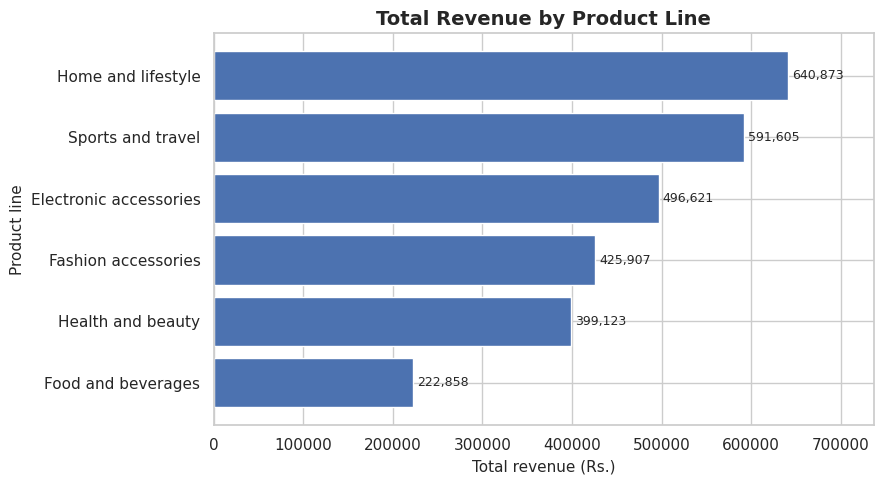

In [41]:
revenue_by_line = df.groupby("product_line")["total"].sum().sort_values()   # smallest to largest

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(revenue_by_line.index, revenue_by_line.values, color=sns.color_palette("deep")[0])
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}" for v in revenue_by_line.values], padding=3, fontsize=9)
ax.set_title("Total Revenue by Product Line")
ax.set_xlabel("Total revenue (Rs.)")
ax.set_ylabel("Product line")
ax.set_xlim(0, revenue_by_line.max() * 1.15)
save_fig("01_revenue_by_product_line.png")

**What the chart tells us:** the bars are ordered from smallest to largest. **Home and lifestyle** is the longest bar and **Food and beverages** is much shorter, less than half of the top bar's revenue. The three highest-earning product lines are also the ones with the highest prices.

### 12.2 Histogram: distribution of invoice totals
**Use:** see the shape of the data: where most values are and how spread out they are.

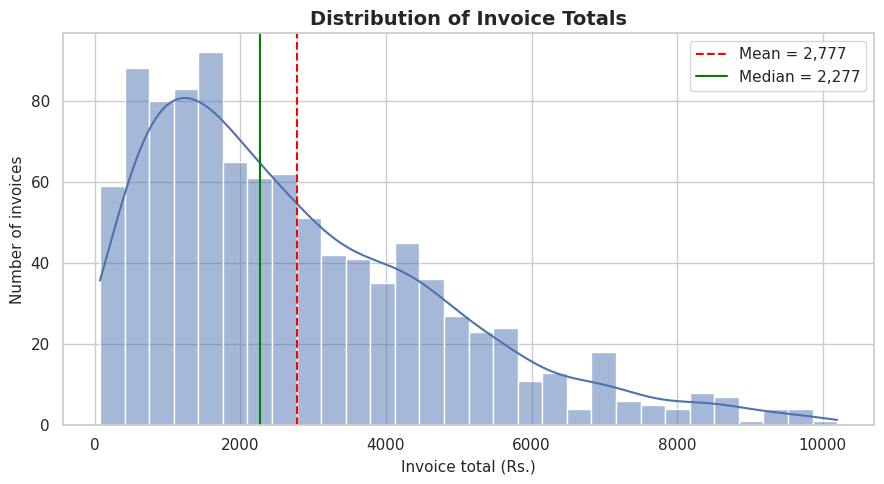

In [42]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["total"], bins=30, kde=True, ax=ax)
ax.axvline(df["total"].mean(), color="red", linestyle="--", label=f"Mean = {df['total'].mean():,.0f}")
ax.axvline(df["total"].median(), color="green", linestyle="-", label=f"Median = {df['total'].median():,.0f}")
ax.set_title("Distribution of Invoice Totals")
ax.set_xlabel("Invoice total (Rs.)")
ax.set_ylabel("Number of invoices")
ax.legend()
save_fig("02_invoice_total_distribution.png")

**What the chart tells us:** most invoices are small or medium and the number of invoices falls steadily as the amount increases, leaving a long tail on the right. This is a **right-skewed** distribution (skewness 1.05). The red mean line (2,777) lies to the right of the green median line (2,277) because the large invoices pull the mean upward.

### 12.3 Box plot: invoice total by branch
**Use:** compare the spread of a number across groups and spot outliers (the dots).

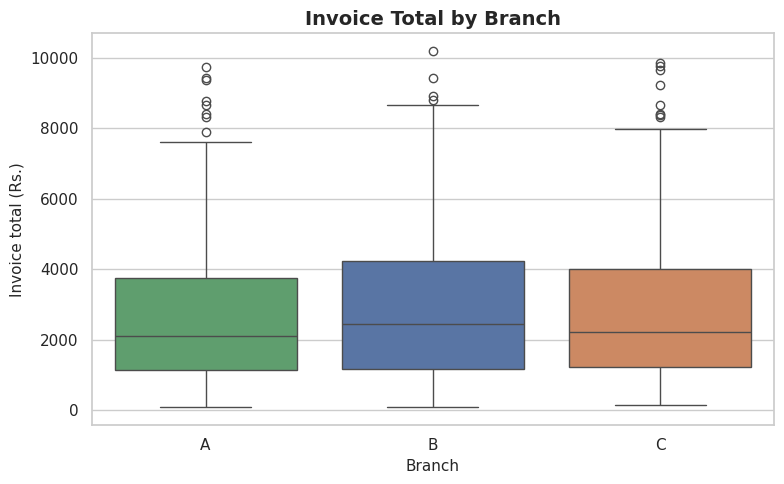

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="branch", y="total", order=["A", "B", "C"], hue="branch", legend=False, ax=ax)
ax.set_title("Invoice Total by Branch")
ax.set_xlabel("Branch")
ax.set_ylabel("Invoice total (Rs.)")
save_fig("03_invoice_total_by_branch.png")

**What the chart tells us:** the box shows the middle 50% of invoices and the line inside is the median. The three branches have very similar boxes, so their typical invoice amounts are alike. The dots above the whiskers are the high-value outlier invoices found in Section 8; each branch has a few.

### 12.4 Pie chart: payment methods
**Use:** show how a total is divided into a few parts (best with 2 to 5 parts).

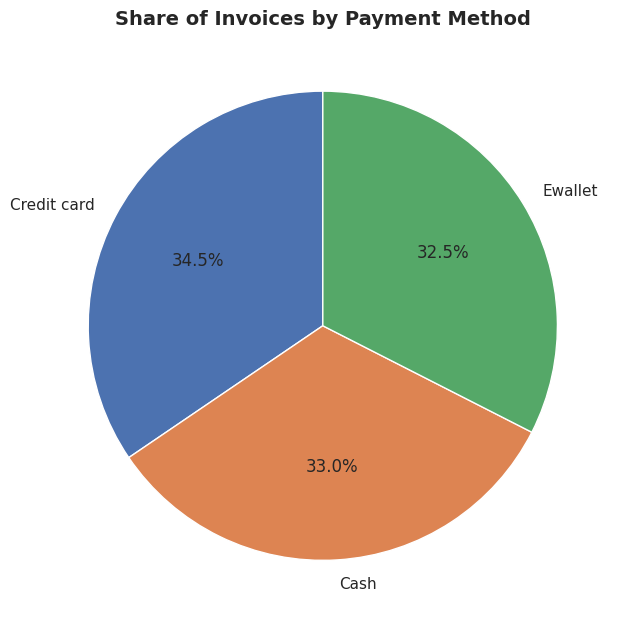

In [44]:
payment_counts = df["payment"].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(payment_counts.values, labels=payment_counts.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("deep")[:3], wedgeprops={"edgecolor": "white"})
ax.set_title("Share of Invoices by Payment Method")
save_fig("04_payment_method_share.png")

**What the chart tells us:** the three slices are almost equal (34.5%, 33.0% and 32.5%), so customers use all three payment methods equally and no method dominates. (A pie chart has no x and y axes; the labels on the slices explain it.)

### 12.5 Scatter plot: rating vs invoice total
**Use:** check whether two numerical variables are related. Each dot is one invoice.

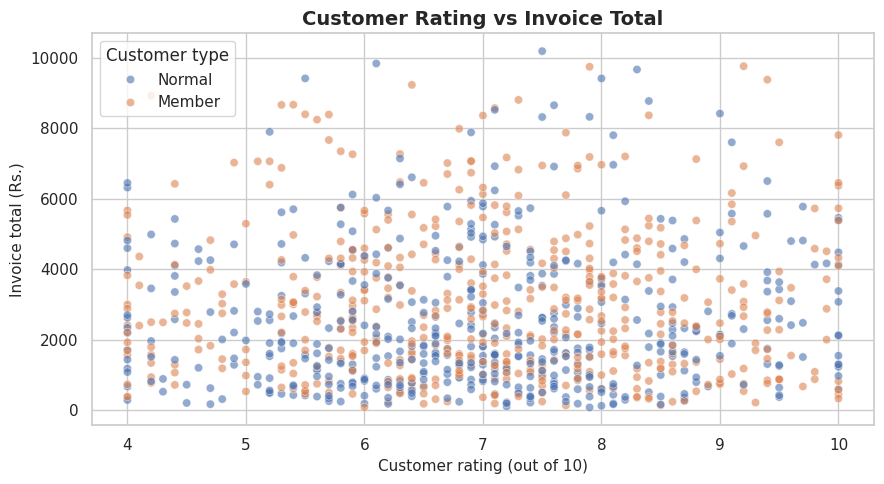

In [45]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="rating", y="total", hue="customer_type", alpha=0.6, ax=ax)
ax.set_title("Customer Rating vs Invoice Total")
ax.set_xlabel("Customer rating (out of 10)")
ax.set_ylabel("Invoice total (Rs.)")
ax.legend(title="Customer type")
save_fig("05_rating_vs_total.png")

**What the chart tells us:** the dots form a shapeless cloud with no upward or downward direction, meaning **no relationship** between rating and amount spent (correlation 0.03). The legend identifies the two customer types; Members tend to have somewhat larger invoices (Question 8), but the two colours are mixed throughout the cloud, which agrees with Question 8.

### 12.6 Line chart: daily revenue over time
**Use:** show how a value changes over time. The thicker line is a 7-day moving average that smooths out day-to-day jumps.

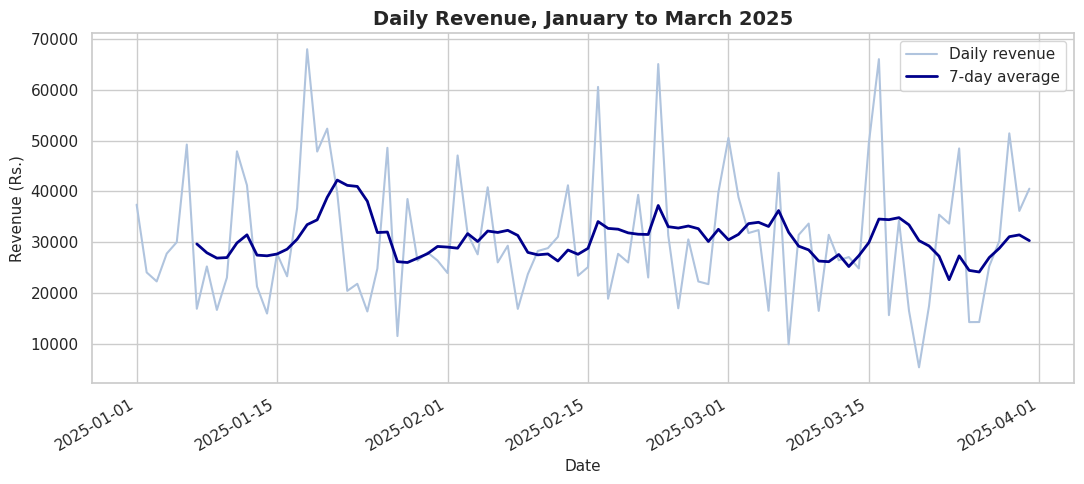

In [46]:
daily_revenue = df.groupby("date")["total"].sum()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_revenue.index, daily_revenue.values, color="lightsteelblue", label="Daily revenue")
ax.plot(daily_revenue.index, daily_revenue.rolling(7).mean(), color="darkblue", linewidth=2, label="7-day average")
ax.set_title("Daily Revenue, January to March 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue (Rs.)")
ax.legend()
fig.autofmt_xdate()
save_fig("07_daily_revenue_trend.png")

**What the chart tells us:** daily revenue jumps up and down a lot (from Rs. 5,413 to Rs. 67,985, the best day was 18 January 2025), but the 7-day average only moves between about Rs. 22,645 and Rs. 42,246 for the whole quarter, rising and falling without a lasting direction. There is **no steady upward or downward trend**, which agrees with Question 6.

### 12.7 Bar chart: revenue by hour of the day
**Use:** find peak times.

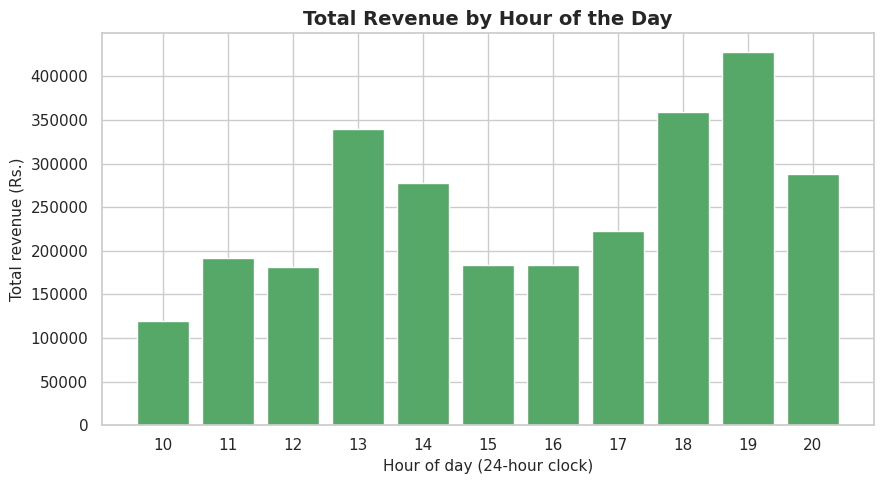

In [47]:
revenue_by_hour = df.groupby("hour")["total"].sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(revenue_by_hour.index, revenue_by_hour.values, color=sns.color_palette("deep")[2])
ax.set_title("Total Revenue by Hour of the Day")
ax.set_xlabel("Hour of day (24-hour clock)")
ax.set_ylabel("Total revenue (Rs.)")
ax.set_xticks(revenue_by_hour.index)
save_fig("08_revenue_by_hour.png")

**What the chart tells us:** there are two clear peaks: around **13:00** (lunch) and in the **evening, 18:00 to 20:00**, with the highest bar at **19:00**. Morning (10:00) is the quietest. A manager could use this to plan staff for the busy hours.

## 13. Correlation Analysis

**Correlation** measures how two numbers move together. It is between -1 and +1:

* **Positive** (towards +1): when one goes up, the other tends to go up.
* **Negative** (towards -1): when one goes up, the other tends to go down.
* **Near 0**: no straight-line relationship (**weak**).
* **Strong** means far from 0 (for example above 0.7 or below -0.7); roughly 0.3 to 0.7 is moderate.

We use `df.corr(numeric_only=True)` on the main numerical columns. (`cogs`, `tax_5pct` and `total` are calculated from price and quantity by a formula, so they are perfectly correlated with each other and would only clutter the result.)

In [48]:
corr_cols = ["unit_price", "quantity", "rating", "total", "hour"]
corr = df[corr_cols].corr(numeric_only=True)
corr.round(2)

,unit_price,quantity,rating,total,hour
unit_price,1.00,-0.02,0.01,0.67,-0.01
quantity,-0.02,1.00,0.01,0.64,0.05
rating,0.01,0.01,1.00,0.03,0.01
total,0.67,0.64,0.03,1.00,0.03
hour,-0.01,0.05,0.01,0.03,1.00


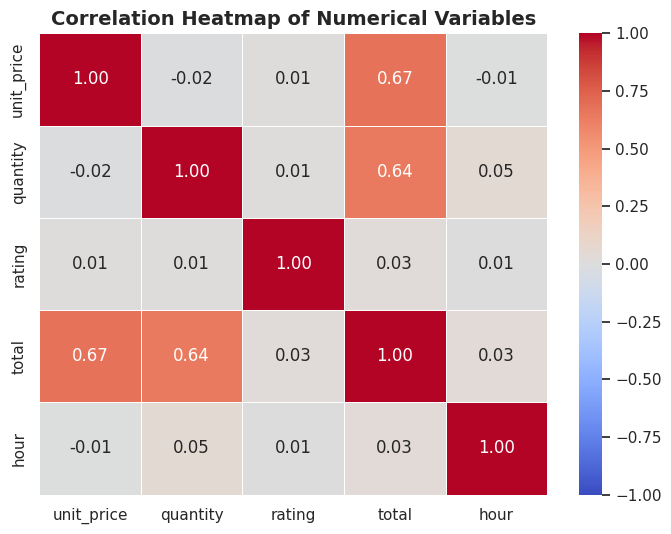

In [49]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Variables")
save_fig("06_correlation_heatmap.png")

**How to read the heatmap:** red means positive correlation, blue means negative, and grey/white means almost none. The diagonal is always 1.00 (each variable with itself).

* **Moderate-to-strong positive:** `total` with `unit_price` (**0.67**) and with `quantity` (**0.64**). This is expected because an invoice total is price multiplied by quantity (plus tax), so this is built into how the number is calculated, not a surprising discovery.
* **Weak:** `rating` with `total` (0.03) and `hour` with `total` (0.03).
* **Almost zero:** `unit_price` with `quantity` (-0.02); customers do not buy fewer items when the price is higher in this data.
* There are **no meaningful negative correlations**.

**Important:** correlation does **not** prove causation. Even if two variables move together, one does not necessarily cause the other.

## 14. Basic Statistical Analysis

We now calculate the main statistics for the numerical columns.

In [50]:
num_cols = ["unit_price", "quantity", "rating", "total"]

stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
stats["Q1 (25%)"] = df[num_cols].quantile(0.25)
stats["Q3 (75%)"] = df[num_cols].quantile(0.75)
stats.round(2)

,mean,median,std,min,max,Q1 (25%),Q3 (75%)
unit_price,454.34,427.47,232.25,50.06,997.58,269.27,608.47
quantity,5.84,6.00,2.82,1.00,10.00,3.00,8.00
rating,7.02,7.00,1.49,4.00,10.00,5.90,8.00
total,2776.99,2277.04,2053.01,74.06,10196.66,1179.42,4007.49


In [51]:
# Mode = the most frequent value (meaningful for categories)
print("Most common product line :", df["product_line"].mode()[0])
print("Most common payment      :", df["payment"].mode()[0])
print("Most common quantity     :", df["quantity"].mode().tolist())
print()

# Spread and shape of invoice totals
q1, q3 = df["total"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:,.2f} | Q3 = {q3:,.2f} | IQR = {iqr:,.2f}")
print(f"Invoices above the outlier limit of {upper:,.2f}: {(df['total'] > upper).sum()}")
print("Skewness of total:", round(df["total"].skew(), 2))

Most common product line : Sports and travel
Most common payment      : Credit card
Most common quantity     : [8]

Q1 = 1,179.42 | Q3 = 4,007.49 | IQR = 2,828.07
Invoices above the outlier limit of 8,249.59: 25
Skewness of total: 1.05


**Explanation in simple language**

* **Mean** is the average (sum divided by count). The mean invoice is Rs. 2,776.99.
* **Median** is the middle value after sorting; half the invoices are smaller and half are larger. It is Rs. 2,277.04. Because the median is lower than the mean, the data is right-skewed.
* **Mode** is the most frequent value. It is useful for categories: the most common product line is **Sports and travel**.
* **Standard deviation (std)** tells how much values typically differ from the mean. For invoice totals it is Rs. 2,053.01, which is large compared with the mean, so invoice amounts vary a lot (because both price and quantity vary).
* **Minimum and maximum** are the smallest and largest values: invoices range from Rs. 74.06 to Rs. 10,196.66.
* **Quartiles** split sorted data into four equal parts. Q1 (25%) is Rs. 1,179.42, the median (50%) is Rs. 2,277.04 and Q3 (75%) is Rs. 4,007.49. The **IQR** (Q3 - Q1) is Rs. 2,828.07. The upper outlier limit is Q3 + 1.5 x IQR = Rs. 8,249.59, and 25 invoices are above it. (This uses the cleaned data, so the numbers differ slightly from Section 8.5, which used the raw data that still contained the duplicates.)
* For **rating**, the mean is 7.02 and the std is 1.49, so most ratings lie between about 5.5 and 8.5.

## 15. Key Insights

Every insight below is supported by the analysis in the sections mentioned. They describe this (synthetic) dataset only.

1. **Size of the data and revenue.** After cleaning, the data has 1000 invoices over 90 days (01 January 2025 to 31 March 2025) with total revenue of Rs. 2,776,985.72 (Section 11, Q1).
2. **A few big invoices raise the average.** The mean invoice (Rs. 2,776.99) is higher than the median (Rs. 2,277.04) and the skewness is 1.05, so the distribution is right-skewed; 25 invoices are above Rs. 8,250 (Q5, Section 14).
3. **Home and lifestyle is the top product line** with Rs. 640,873 (23.1% of revenue) and **Food and beverages is the lowest** with Rs. 222,858 (8.0%). The difference comes from price, because the number of invoices is similar for all lines (Q2).
4. **Branches are close.** Branch C (Bengaluru) leads with Rs. 965,691, and Branch A (Mumbai) is lowest with Rs. 851,038, about 12% less (Q3).
5. **Payment methods are evenly used:** Credit card 34.5%, Cash 33.0%, Ewallet 32.5% (Q4, pie chart).
6. **Members spend more per invoice** (Rs. 3,008 vs Rs. 2,529, about 19% more) because they buy more items (6.30 vs 5.35), not because they buy dearer products (Q8).
7. **Two daily peaks:** lunchtime (13:00) and evening (18:00 to 20:00); the single busiest hour is 19:00 with Rs. 427,927 (Q7, bar chart).
8. **Weekends are busier:** Saturday and Sunday bring 38.1% of revenue from 2 of 7 days. Average revenue per weekend day is Rs. 40,651 against Rs. 26,876 per weekday (Q7).
9. **No growth trend in the quarter.** Revenue per day was about the same in January, February and March; February is lower only because it is a shorter month (Q6, line chart).
10. **Ratings do not depend on spending.** The correlation between rating and total is 0.03; average ratings are similar across product lines and branches (Q10, Section 13).
11. **Revenue is driven by price and quantity.** `total` correlates 0.67 with `unit_price` and 0.64 with `quantity`; price and quantity are not related to each other (-0.02) (Section 13).
12. **Data quality matters.** Cleaning removed 6 duplicate invoices, filled 12 missing ratings and fixed 8 payment spellings into 3. Without this, revenue would have been overstated and the payment counts wrong (Sections 8 and 9).

## 16. Conclusion

**What was done:** we set up a Python data-analysis environment and used Jupyter Notebook to analyse a supermarket sales dataset of 1006 raw records. We explored the data, found and fixed data-quality problems (duplicates, missing ratings, inconsistent payment text, text dates), manipulated the data with pandas, answered 10 EDA questions, created 8 charts, calculated correlations and statistics and wrote 12 insights.

**What was learned:** a good analysis starts with understanding and cleaning the data. The mean can be misleading for skewed data, so we also check the median. Charts and numbers support each other, and correlation must never be mistaken for causation.

**What the analysis revealed:** revenue is driven mostly by product price and quantity; Home and lifestyle earns the most; Members buy more items per invoice; the busiest times are lunchtime, evenings and weekends; and ratings are not related to spending.

**How Python helped:** pandas let us clean and summarise 1000 invoices in a few lines each, Matplotlib and Seaborn turned the results into clear charts, and the notebook kept code, results and explanations together so that anyone can re-run and verify the work.

**Limitation:** the dataset is synthetic, so the findings describe this file and must not be presented as facts about a real supermarket.

## 17. Future Scope

* **Real and larger datasets:** repeat the analysis on a real public dataset (for example the Kaggle *Supermarket sales* data) or on several years of real data.
* **Machine learning (optional next step):** build a model to predict the invoice total or to group customers (clustering).
* **Predictive analytics:** forecast daily revenue and plan stock and staff.
* **Interactive dashboards:** present the results in Power BI, Tableau, Streamlit or Plotly Dash.
* **Real-time data:** connect to a live sales database instead of a CSV file.
* **Advanced statistics:** hypothesis tests (for example a t-test for Member vs Normal customers) and confidence intervals.

*End of notebook.*

In [52]:
# Final check: which charts were saved?
print("Charts saved in", FIG_DIR.resolve().name + ":")
for path in sorted(FIG_DIR.glob("*.png")):
    print(" -", path.name)

Charts saved in visualizations:
 - 01_revenue_by_product_line.png
 - 02_invoice_total_distribution.png
 - 03_invoice_total_by_branch.png
 - 04_payment_method_share.png
 - 05_rating_vs_total.png
 - 06_correlation_heatmap.png
 - 07_daily_revenue_trend.png
 - 08_revenue_by_hour.png
